# Tests for `kernel.py`: Mercer kernels and kernel ridge regression

- **Data convention**, as in `dynamics.py` and `edmd.py`: samples are **columns**, $X \in \mathbb{R}^{d\times N}$, and $K_{ij} = k(x_i, x'_j)$.
- **Kernels:** Gaussian, Matérn (RKHS $H^s(\mathbb{R}^d)$), Wendland, linear, linear-Gaussian, linear-Matérn and linear-Wendland.
- **Operations:** kernel arithmetic, gradients $\partial_x k(x, x')$, and kernel ridge regression (KRR) with closed-form leave-one-out (LOO) selection of $\lambda$.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from kernel import (MercerKernel, gaussian_kernel, matern_kernel, linear_kernel,
                    linear_gaussian_kernel, linear_matern_kernel, wendland_kernel, linear_wendland_kernel)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=5, suppress=True)
rng = np.random.default_rng(0)

def fit_by_loo(k, X, Y, lams=np.logspace(-10, 0, 21)):
    """KRR with lambda chosen by the closed-form leave-one-out error; returns (model, [(lam, loo)])."""
    table = [(lam, k.fit(X, Y, lam).loo_mse()) for lam in lams]
    lam_best = min(table, key=lambda t: t[1])[0]
    return k.fit(X, Y, lam_best), np.array(table)

## Part 1. Kernel definitions

### 1.1 The kernels and their Gram matrices

A Mercer kernel must give symmetric positive semidefinite Gram matrices. We check symmetry and the smallest eigenvalue on 200 random points in $[-1,1]^2$.

In [2]:
d = 2
kernels = {
    "Gaussian (σ=0.5)":              gaussian_kernel(0.5),
    "Matérn (d=2, s=2, ℓ=0.5)":     matern_kernel(d, 2.0, 0.5),
    "Matérn (d=2, s=3.5, ℓ=0.5)":   matern_kernel(d, 3.5, 0.5),
    "Linear":                        linear_kernel(),
    "Linear-Gaussian (σ=0.5)":       linear_gaussian_kernel(0.5),
    "Linear-Matérn (d=2, s=2.5, ℓ=0.5)": linear_matern_kernel(d, 2.5, 0.5),
    "Wendland (d=2, k=1, ρ=1)":       wendland_kernel(d, 1, 1.0),
    "Linear-Wendland (d=2, k=1, ρ=1)": linear_wendland_kernel(d, 1, 1.0),
}
X = rng.uniform(-1, 1, (d, 200))
for name, k in kernels.items():
    K = k.matrix(X)
    ev = np.linalg.eigvalsh(K)
    print(f"{name:36s} {k.name:38s} k(x,x) at x=(0.3,-0.2): {k([0.3, -0.2], [0.3, -0.2]):.4f} | "
          f"symmetric: {np.allclose(K, K.T)} | min eig / max eig = {ev[0] / ev[-1]: .1e}")

Gaussian (σ=0.5)                     Gaussian(sigma=0.5)                    k(x,x) at x=(0.3,-0.2): 1.0000 | symmetric: True | min eig / max eig = -2.7e-17
Matérn (d=2, s=2, ℓ=0.5)             Matern(d=2, s=2, nu=1, l=0.5)          k(x,x) at x=(0.3,-0.2): 1.0000 | symmetric: True | min eig / max eig =  3.7e-06
Matérn (d=2, s=3.5, ℓ=0.5)           Matern(d=2, s=3.5, nu=2.5, l=0.5)      k(x,x) at x=(0.3,-0.2): 1.0000 | symmetric: True | min eig / max eig =  2.1e-10
Linear                               Linear                                 k(x,x) at x=(0.3,-0.2): 0.1300 | symmetric: True | min eig / max eig = -3.3e-16
Linear-Gaussian (σ=0.5)              Linear-Gaussian(sigma=0.5)             k(x,x) at x=(0.3,-0.2): 0.1300 | symmetric: True | min eig / max eig = -6.7e-17
Linear-Matérn (d=2, s=2.5, ℓ=0.5)    Linear-Matern(d=2, s=2.5, l=0.5)       k(x,x) at x=(0.3,-0.2): 0.1300 | symmetric: True | min eig / max eig =  5.5e-08
Wendland (d=2, k=1, ρ=1)             Wendland(d=2, k=1, rho=1)  

### 1.2 Matérn kernel: closed forms and smoothness

With $\nu = s - d/2$, $k(r) = \frac{2^{1-\nu}}{\Gamma(\nu)} r^\nu K_\nu(r)$. For half-integer $\nu$ this reduces to the Matérn closed forms:

| $\nu$ | $k(r)$ |
|---|---|
| $1/2$ | $e^{-r}$ |
| $3/2$ | $(1+r)e^{-r}$ |
| $5/2$ | $(1+r+r^2/3)e^{-r}$ |

The kernel depends on $(d, s)$ only through $\nu$; e.g. $d=3$, $s=2$ gives $\nu = 1/2$. Larger $s$ gives a smoother kernel, which approaches a Gaussian as $s\to\infty$.

d=1, s=1.0: nu=0.5, max |k - Matern closed form| = 3.3e-16
d=1, s=2.0: nu=1.5, max |k - Matern closed form| = 6.7e-16
d=1, s=3.0: nu=2.5, max |k - Matern closed form| = 6.7e-16
d=3, s=2.0: nu=0.5, max |k - Matern closed form| = 3.3e-16
d=2, s=2.5: nu=1.5, max |k - Matern closed form| = 6.7e-16


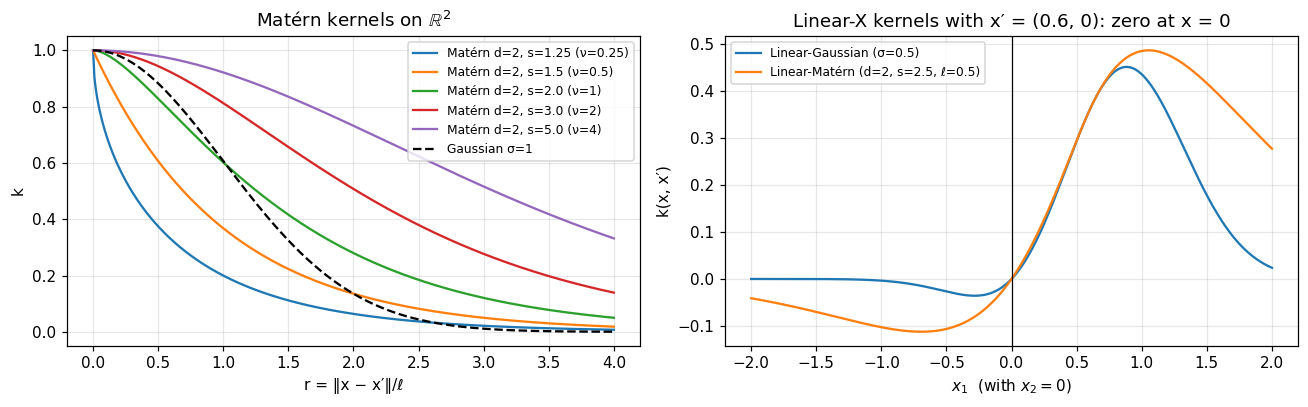

In [3]:
r = np.linspace(0, 4, 401)
pts = np.vstack([r, np.zeros_like(r)])           # distance r from the origin (d = 2 embedding)
closed = {0.5: np.exp(-r), 1.5: (1 + r) * np.exp(-r), 2.5: (1 + r + r ** 2 / 3) * np.exp(-r)}
for dd, ss in [(1, 1.0), (1, 2.0), (1, 3.0), (3, 2.0), (2, 2.5)]:
    k = matern_kernel(dd, ss)
    P = np.vstack([r] + [np.zeros_like(r)] * (dd - 1))
    vals = k.matrix(np.zeros((dd, 1)), P)[0]
    nu = ss - dd / 2
    print(f"d={dd}, s={ss}: nu={nu}, max |k - Matern closed form| = {np.max(np.abs(vals - closed[nu])):.1e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for ss in [1.25, 1.5, 2.0, 3.0, 5.0]:
    ax[0].plot(r, matern_kernel(2, ss).matrix(np.zeros((2, 1)), pts)[0], label=f"Matérn d=2, s={ss} (ν={ss-1:g})")
ax[0].plot(r, np.exp(-r ** 2 / 2), "k--", label="Gaussian σ=1")
ax[0].set(xlabel="r = ‖x − x′‖/ℓ", ylabel="k", title="Matérn kernels on $\\mathbb{R}^2$"); ax[0].legend(fontsize=8)
for name in ["Linear-Gaussian (σ=0.5)", "Linear-Matérn (d=2, s=2.5, ℓ=0.5)"]:
    xp = np.array([[0.6], [0.0]])
    ax[1].plot(r - 2, kernels[name].matrix(np.vstack([r - 2, np.zeros_like(r)]), xp)[:, 0], label=name)
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set(xlabel="$x_1$  (with $x_2 = 0$)", ylabel="k(x, x′)", title="Linear-X kernels with x′ = (0.6, 0): zero at x = 0")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 1.3 Kernel arithmetic

Sums, products and positive scaling are each checked against the corresponding operation on Gram matrices. A non-positive scale raises an error.

In [4]:
kg, ks, kl = gaussian_kernel(0.7), matern_kernel(2, 2.5, 0.6), linear_kernel()
Xa, Xb = rng.uniform(-1, 1, (2, 30)), rng.uniform(-1, 1, (2, 20))
G, S, L = kg.matrix(Xa, Xb), ks.matrix(Xa, Xb), kl.matrix(Xa, Xb)
checks = {
    "k_g + k_s":          (kg + ks, G + S),
    "k_g * k_s":          (kg * ks, G * S),
    "3 * k_s":            (3 * ks, 3 * S),
    "k_s * 0.5":          (ks * 0.5, 0.5 * S),
    "2 k_l k_g + k_s":    (2 * kl * kg + ks, 2 * L * G + S),
}
for name, (k, ref) in checks.items():
    print(f"{name:16s} -> {k.name:58s} max error = {np.max(np.abs(k.matrix(Xa, Xb) - ref)):.1e}")
print("linear_gaussian_kernel == linear * gaussian:",
      np.allclose(linear_gaussian_kernel(0.7).matrix(Xa, Xb), L * G))
for bad in ("-1 * kg", "0 * kg"):
    try:
        eval(bad); print(bad, "-> accepted (unexpected)")
    except (ValueError, TypeError) as e:
        print(f"{bad:10s} -> rejected: {e}")

k_g + k_s        -> (Gaussian(sigma=0.7) + Matern(d=2, s=2.5, nu=1.5, l=0.6))  max error = 0.0e+00
k_g * k_s        -> (Gaussian(sigma=0.7) * Matern(d=2, s=2.5, nu=1.5, l=0.6))  max error = 0.0e+00
3 * k_s          -> 3 * Matern(d=2, s=2.5, nu=1.5, l=0.6)                      max error = 0.0e+00
k_s * 0.5        -> 0.5 * Matern(d=2, s=2.5, nu=1.5, l=0.6)                    max error = 0.0e+00
2 k_l k_g + k_s  -> ((2 * Linear * Gaussian(sigma=0.7)) + Matern(d=2, s=2.5, nu=1.5, l=0.6)) max error = 0.0e+00
linear_gaussian_kernel == linear * gaussian: True
-1 * kg    -> rejected: A kernel can only be scaled by a positive constant.
0 * kg     -> rejected: A kernel can only be scaled by a positive constant.


### 1.4 Gradients $\partial_x k(x, x')$

The analytic gradients are compared with central finite differences, for all kernels and for a composite kernel. The Matérn kernel is differentiable when $\nu > 1/2$, i.e. $s > (d+1)/2$.

In [5]:
def fd_grad(k, X, Xp, h=1e-6):
    G = np.zeros((X.shape[0], X.shape[1], Xp.shape[1]))
    for a in range(X.shape[0]):
        E = np.zeros_like(X); E[a] = h
        G[a] = (k.matrix(X + E, Xp) - k.matrix(X - E, Xp)) / (2 * h)
    return G

Xa, Xb = rng.uniform(-1, 1, (2, 15)), rng.uniform(-1, 1, (2, 12))
all_k = dict(kernels)
all_k["composite: 2 k_lin k_gauss + k_sob"] = 2 * linear_kernel() * gaussian_kernel(0.7) + matern_kernel(2, 3.0)
for name, k in all_k.items():
    if not k.has_grad:
        print(f"{name:40s} no gradient (nu <= 1/2)"); continue
    Ga, Gf = k.grad(Xa, Xb), fd_grad(k, Xa, Xb)
    print(f"{name:40s} max |analytic - FD| / max |grad| = {np.max(np.abs(Ga - Gf)) / np.max(np.abs(Gf)):.1e}")
print("gradient at coincident points (Matérn s=3, d=2):", matern_kernel(2, 3.0).grad(Xa[:, :1], Xa[:, :1]).ravel())
print("Matérn d=2, s=1.25 (nu = 0.25) has a gradient:", matern_kernel(2, 1.25).has_grad)

Gaussian (σ=0.5)                         max |analytic - FD| / max |grad| = 2.2e-10
Matérn (d=2, s=2, ℓ=0.5)                 max |analytic - FD| / max |grad| = 5.3e-10
Matérn (d=2, s=3.5, ℓ=0.5)               max |analytic - FD| / max |grad| = 5.3e-10
Linear                                   max |analytic - FD| / max |grad| = 5.6e-11
Linear-Gaussian (σ=0.5)                  max |analytic - FD| / max |grad| = 2.1e-10
Linear-Matérn (d=2, s=2.5, ℓ=0.5)        max |analytic - FD| / max |grad| = 2.1e-10
Wendland (d=2, k=1, ρ=1)                 max |analytic - FD| / max |grad| = 3.9e-10
Linear-Wendland (d=2, k=1, ρ=1)          max |analytic - FD| / max |grad| = 4.0e-10
composite: 2 k_lin k_gauss + k_sob       max |analytic - FD| / max |grad| = 1.7e-10
gradient at coincident points (Matérn s=3, d=2): [0. 0.]
Matérn d=2, s=1.25 (nu = 0.25) has a gradient: False


### 1.5 Kernel matrices and feature maps

- `k.matrix(X)` and `k.matrix(X, Xp)` give the Gram and cross matrices for any data set, with samples as columns.
- `phi = k.feature_map(X_data)` gives the map $\varphi(x) = [k(x,x_1), \dots, k(x,x_N)]^\top$:
  - `phi(x)` has shape $(N,)$, or $(N, M)$ for several points;
  - `phi.jacobian(x)` has shape $(N, d)$;
  - `phi.casadi(x)` is a symbolic $(N, 1)$ expression.

**Checks:**
- $\varphi$ agrees with the kernel matrix, its Jacobian with finite differences, and its CasADi version with NumPy.

In [6]:
import casadi as ca
Xd = rng.uniform(-1, 1, (2, 50))                 # data points x_1..x_N
Xq = rng.uniform(-1, 1, (2, 7))                  # query points
for name, k in [("Matérn s=2.5", matern_kernel(2, 2.5, 0.5)), ("Linear-Wendland", linear_wendland_kernel(2, 1, 1.0))]:
    phi = k.feature_map(Xd)
    v1 = phi(Xq[:, 0])                                           # (N,)
    V = phi(Xq)                                                  # (N, M)
    J = phi.jacobian(Xq[:, 0])                                   # (N, d)
    h = 1e-6
    Jfd = np.column_stack([(phi(Xq[:, 0] + h * e) - phi(Xq[:, 0] - h * e)) / (2 * h) for e in np.eye(2)])
    xs = ca.SX.sym("x", 2)
    vc = np.asarray(ca.Function("phi", [xs], [phi.casadi(xs)])(Xq[:, 0])).ravel()
    print(f"{name:16s} {phi}: shapes {v1.shape}, {V.shape}, {J.shape} | "
          f"|phi(x) - K[:, x]| = {np.max(np.abs(V - k.matrix(Xd, Xq))):.1e}, "
          f"|J - FD| = {np.max(np.abs(J - Jfd)):.1e}, |CasADi - NumPy| = {np.max(np.abs(vc - v1)):.1e}")


Matérn s=2.5     KernelFeatureMap(kernel='Matern(d=2, s=2.5, nu=1.5, l=0.5)', N=50): shapes (50,), (50, 7), (50, 2) | |phi(x) - K[:, x]| = 0.0e+00, |J - FD| = 2.4e-10, |CasADi - NumPy| = 7.8e-16
Linear-Wendland  KernelFeatureMap(kernel='Linear-Wendland(d=2, k=1, rho=1)', N=50): shapes (50,), (50, 7), (50, 2) | |phi(x) - K[:, x]| = 0.0e+00, |J - FD| = 1.0e-09, |CasADi - NumPy| = 2.0e-15


## Part 2. Kernel ridge regression

### 2.1 One dimension: noisy data, LOO selection of λ

Target: $f(x) = \sin(3x) + 0.5x$ on $[-1,1]$, 40 samples, noise standard deviation 0.05. The regularization $\lambda$ is chosen by the closed-form LOO error (`loo_mse`), which we verify against brute-force leave-one-out for one kernel.

The linear-X kernels force $f(0) = 0$. The target satisfies this, so it suits them.

Gaussian σ=0.3                   λ* = 1.0e-01, LOO MSE = 3.38e-03, f(0) =  7.06e-03
Matérn d=1, s=2, ℓ=0.3           λ* = 1.0e-02, LOO MSE = 3.43e-03, f(0) = -1.80e-02
Linear-Gaussian σ=0.3            λ* = 3.2e-03, LOO MSE = 3.38e-03, f(0) =  0.00e+00


Linear-Matérn d=1, s=2, ℓ=0.3    λ* = 1.0e-02, LOO MSE = 3.38e-03, f(0) =  0.00e+00


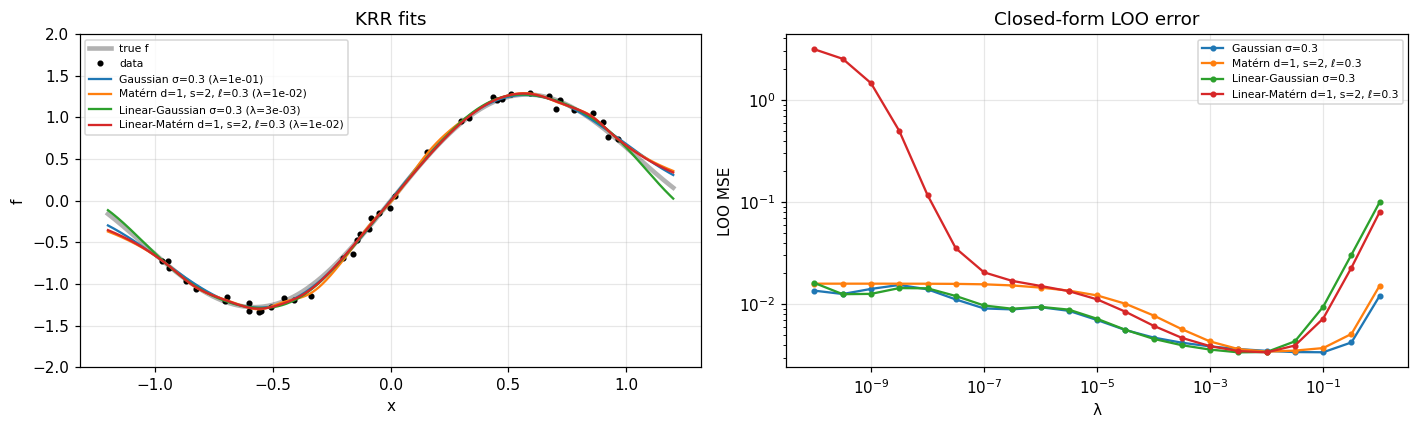

closed-form vs brute-force LOO residuals: max difference = 3.6e-13


In [7]:
f_true = lambda x: np.sin(3 * x) + 0.5 * x
Xtr = rng.uniform(-1, 1, (1, 40)); Ytr = f_true(Xtr[0]) + 0.05 * rng.normal(size=40)
Xte = np.linspace(-1.2, 1.2, 400)[None]
k1d = {
    "Gaussian σ=0.3": gaussian_kernel(0.3),
    "Matérn d=1, s=2, ℓ=0.3": matern_kernel(1, 2.0, 0.3),
    "Linear-Gaussian σ=0.3": linear_gaussian_kernel(0.3),
    "Linear-Matérn d=1, s=2, ℓ=0.3": linear_matern_kernel(1, 2.0, 0.3),
}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(Xte[0], f_true(Xte[0]), "k", lw=3, alpha=0.3, label="true f")
ax[0].plot(Xtr[0], Ytr, "k.", label="data")
for name, k in k1d.items():
    mdl, loo_table = fit_by_loo(k, Xtr, Ytr)
    ax[0].plot(Xte[0], mdl.predict(Xte), label=f"{name} (λ={mdl.regularization:.0e})")
    ax[1].loglog(loo_table[:, 0], loo_table[:, 1], "o-", ms=3, label=name)
    print(f"{name:32s} λ* = {mdl.regularization:.1e}, LOO MSE = {mdl.loo_mse():.2e}, "
          f"f(0) = {mdl.predict(np.zeros((1, 1)))[0]: .2e}")
ax[0].set(xlabel="x", ylabel="f", ylim=(-2, 2), title="KRR fits"); ax[0].legend(fontsize=7)
ax[1].set(xlabel="λ", ylabel="LOO MSE", title="Closed-form LOO error"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# brute-force check of the closed-form LOO residuals
k, lam = k1d["Matérn d=1, s=2, ℓ=0.3"], 1e-3
mdl = k.fit(Xtr, Ytr, lam)
bf = np.array([Ytr[i] - k.fit(np.delete(Xtr, i, 1), np.delete(Ytr, i), lam).predict(Xtr[:, i:i+1])[0]
               for i in range(Xtr.shape[1])])
print(f"closed-form vs brute-force LOO residuals: max difference = {np.max(np.abs(mdl.loo_residuals() - bf)):.1e}")

### 2.2 Vector-valued targets and gradients: learning the CSTR drift

Targets with $p$ outputs are fitted in one solve, with $Y \in \mathbb{R}^{p\times N}$. As a test related to the paper, we learn the drift $\tilde f_0$ of the scaled CSTR from `test_dynamics.ipynb` on the box $|z_1| \le 0.3$, $|z_2| \le 0.03$:

- the test error as the number of samples $N$ grows, for each kernel;
- the Jacobian of the KRR model at the origin, `predict_gradient`, against the true linearization $A$.

The drift vanishes at the origin, so the linear-X kernels are a natural fit. We use the box-normalized coordinates $w = z/L$, which give all inputs a comparable scale.

Gaussian σ=1                 N=640: rel. RMS test error = 2.8e-07, rel. Jacobian error at 0 = 3.1e-07, F(0) = [ 0. -0.]


Matérn d=2, s=2.5, ℓ=1       N=640: rel. RMS test error = 4.9e-04, rel. Jacobian error at 0 = 6.5e-07, F(0) = [ 0. -0.]


Linear-Gaussian σ=1          N=640: rel. RMS test error = 9.1e-08, rel. Jacobian error at 0 = 2.2e-07, F(0) = [0. 0.]


Linear-Matérn d=2, s=2.5     N=640: rel. RMS test error = 2.1e-04, rel. Jacobian error at 0 = 3.2e-06, F(0) = [0. 0.]


Wendland d=2, k=1, ρ=1.5     N=640: rel. RMS test error = 2.3e-03, rel. Jacobian error at 0 = 1.2e-03, F(0) = [-0.00036  0.0006 ]


Linear-Wendland d=2, k=1, ρ=1.5 N=640: rel. RMS test error = 1.7e-03, rel. Jacobian error at 0 = 1.7e-04, F(0) = [0. 0.]


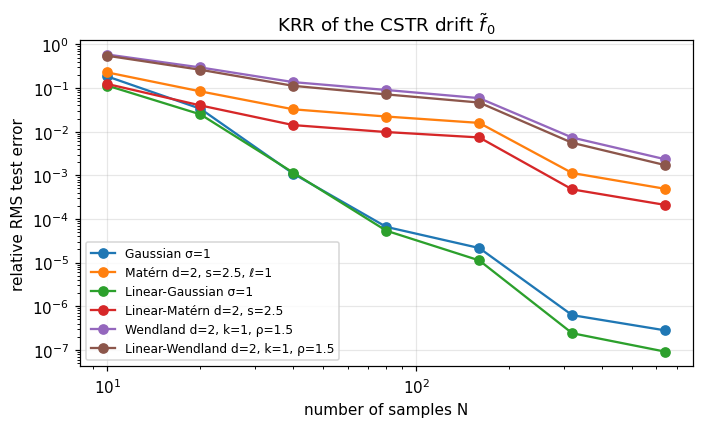

In [8]:
from dynamics import InputAffineSystem
V, k0, E, Rg, dH, rho, cp, T0, CA0 = 1.0, 8.46e6, 5.0e4, 8.314, -1.15e4, 1000.0, 0.231, 300.0, 4.0
def f0(x):
    CA, T = x
    r = k0 * np.exp(-E / (Rg * T)) * CA
    return np.array([-r, -dH / (rho * cp) * r])
f1 = lambda x: np.array([(CA0 - x[0]) / V, (T0 - x[1]) / V])
f2 = lambda x: np.array([0.0, 1.0 / (rho * cp * V)])
cstr = InputAffineSystem(f0, [f1, f2], 2, 2, name="CSTR", x_test=[2.0, 400.0])
s = cstr.shift_to_steady_state([5.0, 2.0e4], x_guess=[1.95, 402.0], scaling="nominal")
w = s.transform(np.zeros(2), [0.3, 0.03], np.zeros(2), np.ones(2), name="CSTR (box-normalized)")
A_true, _ = w.linearize()

drift = lambda W: np.column_stack([w.f0(W[:, i]) for i in range(W.shape[1])])
W_test = w.sample_hypercube(2000, 1.0, rng=99); F_test = drift(W_test)
k2d = {
    "Gaussian σ=1":               gaussian_kernel(1.0),
    "Matérn d=2, s=2.5, ℓ=1":    matern_kernel(2, 2.5, 1.0),
    "Linear-Gaussian σ=1":        linear_gaussian_kernel(1.0),
    "Linear-Matérn d=2, s=2.5":  linear_matern_kernel(2, 2.5, 1.0),
    "Wendland d=2, k=1, ρ=1.5":   wendland_kernel(2, 1, 1.5),
    "Linear-Wendland d=2, k=1, ρ=1.5": linear_wendland_kernel(2, 1, 1.5),
}
Ns = [10, 20, 40, 80, 160, 320, 640]
err, jac = {n: [] for n in k2d}, {}
for name, k in k2d.items():
    for N in Ns:
        Wtr = w.sample_hypercube(N, 1.0, rng=1)
        mdl, _ = fit_by_loo(k, Wtr, drift(Wtr), np.logspace(-12, -2, 11))
        err[name].append(np.sqrt(np.mean((mdl.predict(W_test) - F_test) ** 2)) / np.sqrt(np.mean(F_test ** 2)))
    J0 = mdl.predict_gradient(np.zeros((2, 1)))[:, :, 0]       # (p, d): dF_p/dw_d at 0
    jac[name] = np.max(np.abs(J0 - A_true)) / np.max(np.abs(A_true))
    print(f"{name:28s} N={Ns[-1]}: rel. RMS test error = {err[name][-1]:.1e}, "
          f"rel. Jacobian error at 0 = {jac[name]:.1e}, F(0) = {mdl.predict(np.zeros((2, 1)))[:, 0]}")

fig, ax = plt.subplots(figsize=(6.5, 4))
for name in k2d:
    ax.loglog(Ns, err[name], "o-", label=name)
ax.set(xlabel="number of samples N", ylabel="relative RMS test error", title="KRR of the CSTR drift $\\tilde f_0$")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()